<a href="https://colab.research.google.com/github/moanshori-repo/WQA-ELM/blob/main/ELM_WQA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files

uploaded = files.upload()

for fn in uploaded.keys():
  print(f'User uploaded file "{fn}" with length {len(uploaded[fn])} bytes')

Saving WQD.xlsx to WQD.xlsx
User uploaded file "WQD.xlsx" with length 925902 bytes


In [ ]:
print("HEHE")

HEHE


In [ ]:
import pandas as pd

df = pd.read_excel('WQD.xlsx')
display(df.head())

,Temp,Turbidity (cm),DO(mg/L),BOD (mg/L),CO2,pH`,Alkalinity (mg L-1 ),Hardness (mg L-1 ),Calcium (mg L-1 ),Ammonia (mg L-1 ),Nitrite (mg L-1 ),Phosphorus (mg L-1 ),H2S (mg L-1 ),Plankton (No. L-1),Water Quality
0,67.448725,10.127148,0.208153,7.473607,10.181084,4.751657,218.364855,300.125080,337.178226,0.286054,4.355310,0.005984,0.066793,6069.624017,2
1,64.626666,94.015595,11.434463,10.859998,14.860521,3.085154,273.939692,8.426776,363.660740,0.096040,2.182753,0.004906,0.023428,250.995959,2
2,65.121842,90.653462,12.430865,12.809970,12.319980,9.648515,220.812730,11.726274,309.370934,0.974501,4.901760,0.006979,0.065041,7218.927473,2
3,1.640334,0.066344,10.963529,8.508023,12.955209,4.819988,266.571628,6.627655,8.180468,0.884865,3.571842,3.174473,0.026018,1230.062252,2
4,64.863434,2.119173,1.361736,13.335372,13.603197,10.244034,252.108000,339.891514,253.996871,0.801695,4.655898,3.854701,0.060995,1035.054820,2


In [ ]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Temp,4300.0,25.695663,9.670202,0.194046,19.775926,25.041849,30.277718,84.251522
Turbidity (cm),4300.0,39.046681,20.942726,0.051424,22.224140,30.205696,55.945735,99.797743
DO(mg/L),4300.0,5.300346,1.832736,0.133928,3.978366,5.000754,6.521225,14.970122
BOD (mg/L),4300.0,3.125079,2.292060,1.000621,1.522077,2.236022,4.324578,14.943006
CO2,4300.0,6.375929,2.831104,0.001155,5.048761,6.598076,8.241532,14.984216
pH`,4300.0,7.713468,1.580282,0.003944,6.443019,7.743176,9.035251,14.851195
Alkalinity (mg L-1 ),4300.0,93.717183,68.949048,25.012328,40.422364,67.562607,132.834386,299.913160
Hardness (mg L-1 ),4300.0,127.055476,78.883091,0.255805,69.479620,111.063301,162.675648,398.796550
Calcium (mg L-1 ),4300.0,84.871932,75.718842,0.018293,23.745078,62.845419,115.596833,399.321398
Ammonia (mg L-1 ),4300.0,0.048269,0.122886,0.000001,0.012750,0.026335,0.039016,0.999300


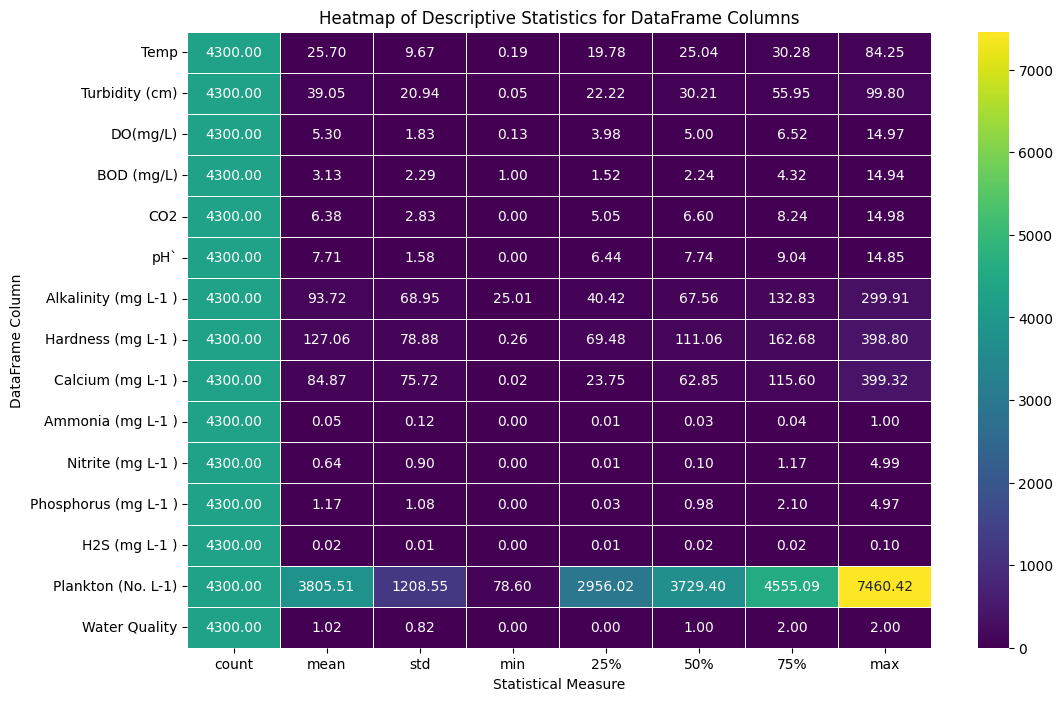

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Get descriptive statistics and transpose for better visualization
df_desc = df.describe().T

# Create a heatmap of the descriptive statistics
plt.figure(figsize=(12, 8))
sns.heatmap(df_desc, annot=True, cmap='viridis', fmt='.2f', linewidths=.5)
plt.title('Heatmap of Descriptive Statistics for DataFrame Columns')
plt.xlabel('Statistical Measure')
plt.ylabel('DataFrame Column')
plt.show()

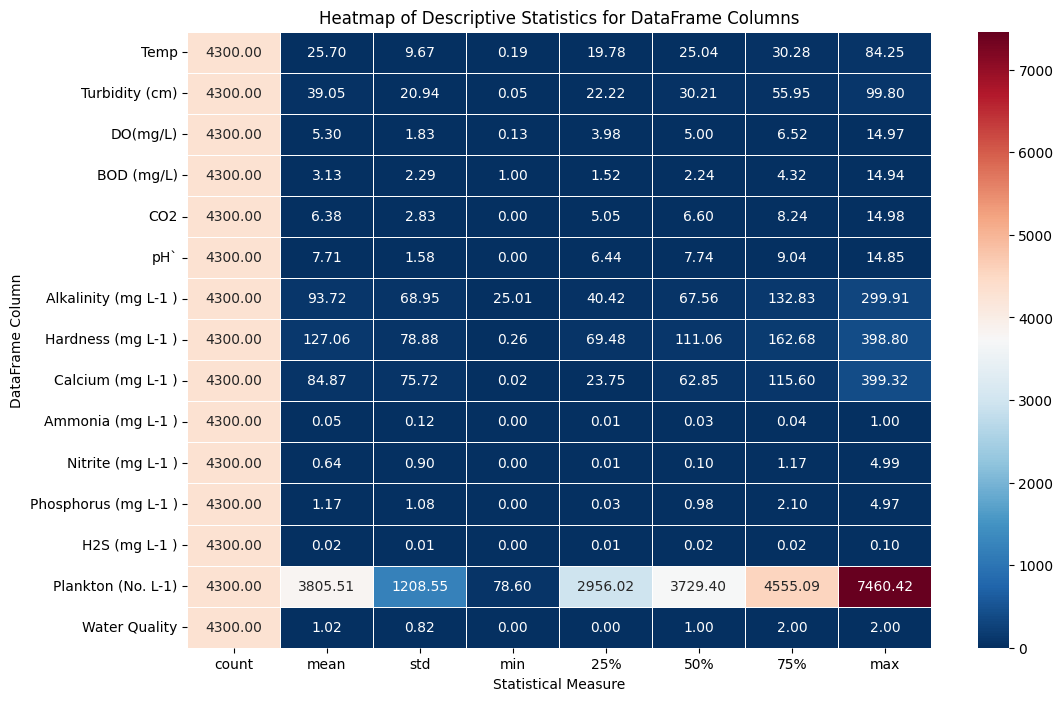

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Get descriptive statistics and transpose for better visualization
df_desc = df.describe().T

# Create a heatmap of the descriptive statistics
plt.figure(figsize=(12, 8))
sns.heatmap(df_desc, annot=True, cmap='RdBu_r', fmt='.2f', linewidths=.5)
plt.title('Heatmap of Descriptive Statistics for DataFrame Columns')
plt.xlabel('Statistical Measure')
plt.ylabel('DataFrame Column')
plt.show()

### Visualizing Outliers using Violin Plots

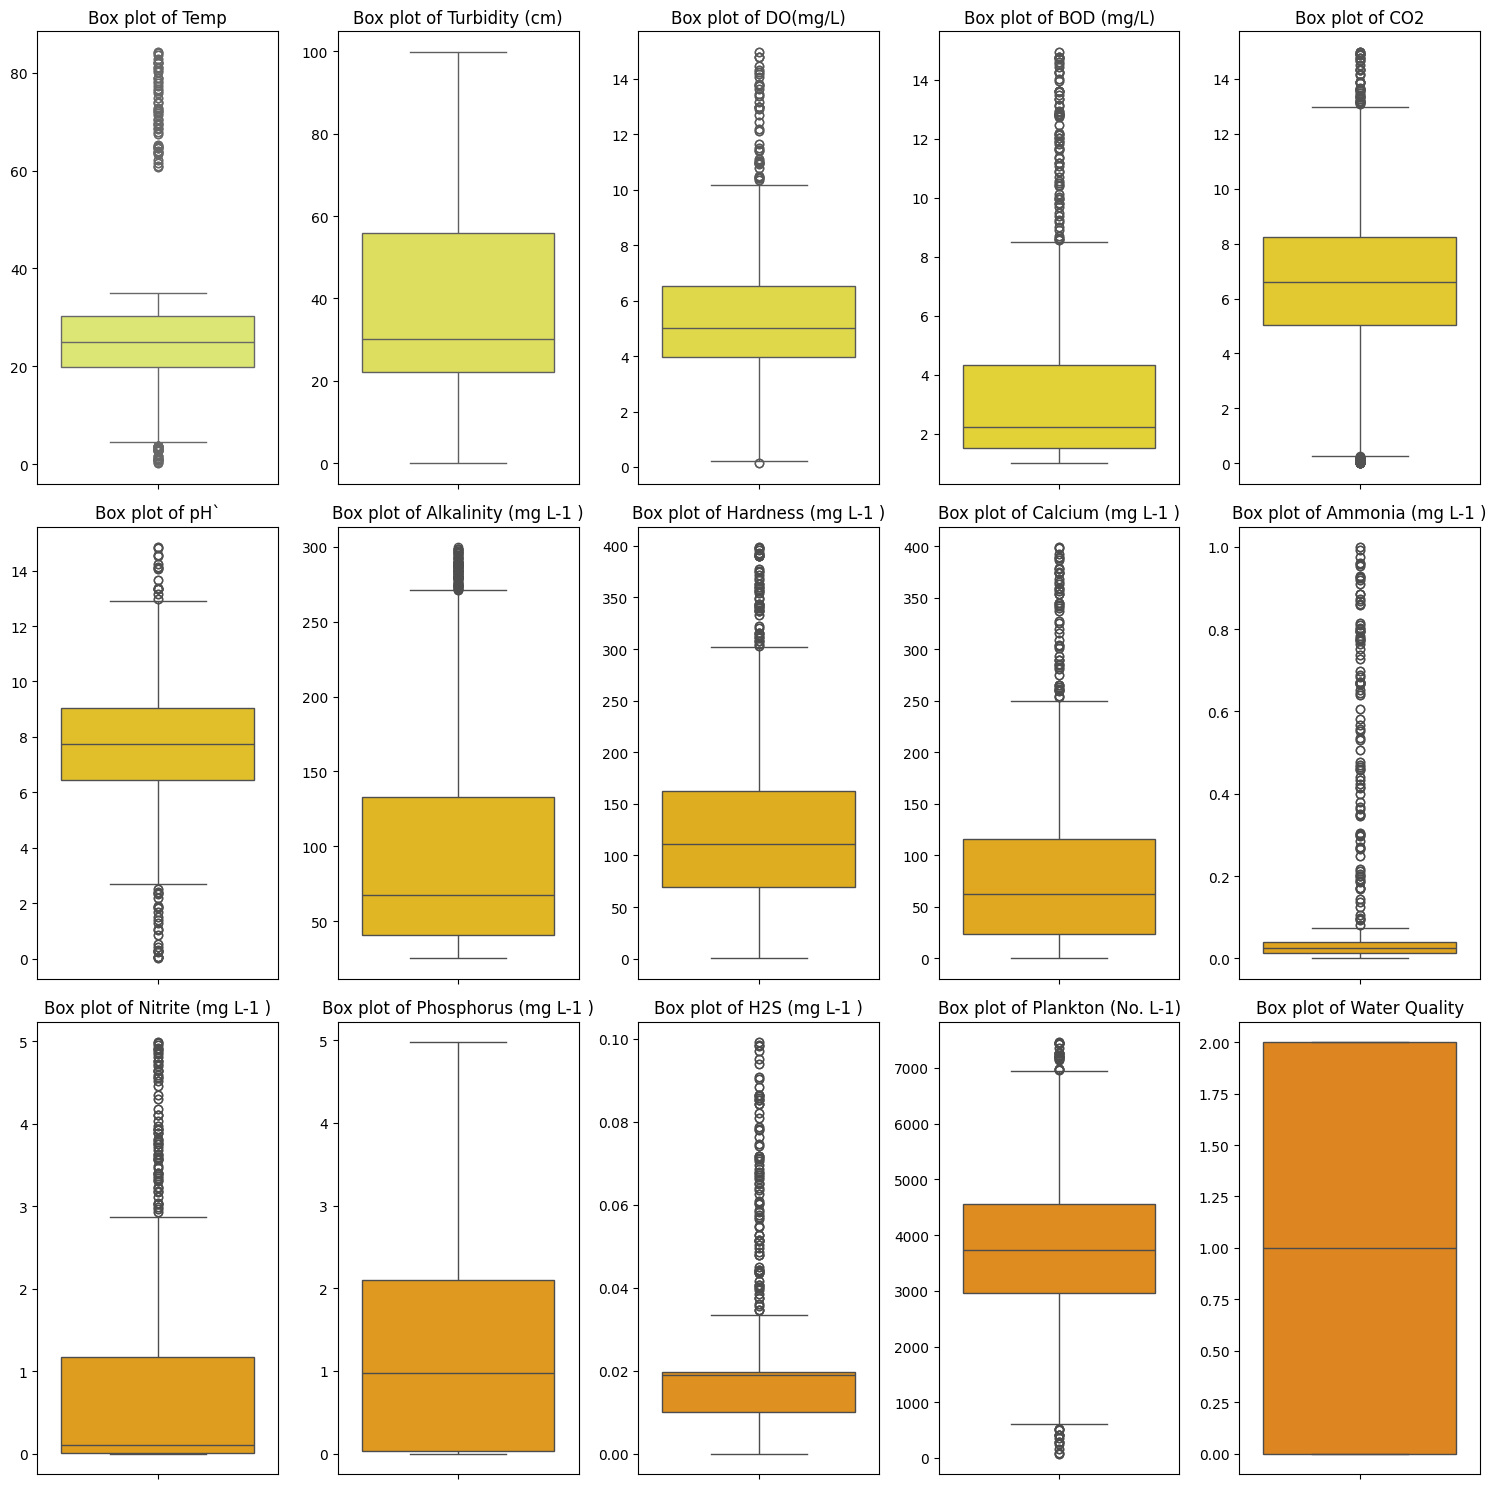

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select only numeric columns for box plotting
numeric_cols = df.select_dtypes(include=['number']).columns

# Determine the number of rows and columns for the subplot grid
# Aim for 3 columns per row for better readability
num_cols_per_row = 5
num_rows = (len(numeric_cols) + num_cols_per_row - 1) // num_cols_per_row

plt.figure(figsize=(15, 5 * num_rows))

# Get a color palette with enough colors for all numeric columns, using 'Wistia' for brown-orange transition
colors = sns.color_palette('Wistia', n_colors=len(numeric_cols))

for i, col in enumerate(numeric_cols):
    plt.subplot(num_rows, num_cols_per_row, i + 1)
    # Assign a specific color from the palette to each box plot
    sns.boxplot(y=df[col], color=colors[i])
    plt.title(f'Box plot of {col}')
    plt.ylabel('') # Remove y-axis label to avoid clutter

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

# Assuming 'y' is already defined from df['Water Quality']
# If not, ensure it's defined: y = df['Water Quality']

# Define the mapping from numerical labels to categorical names
quality_mapping = {
    0: 'Excellent',
    1: 'Good',
    2: 'Poor'
}

y = df['Water Quality']

# Create a new Series 'y_categorical' by mapping the values
y_categorical = y.map(quality_mapping)

print("Head of the new categorical 'Water Quality' Series:")
display(y_categorical.head())

print("Value counts of the new categorical 'Water Quality' Series:")
display(y_categorical.value_counts())

Head of the new categorical 'Water Quality' Series:


,Water Quality
0,Poor
1,Poor
2,Poor
3,Poor
4,Poor


Value counts of the new categorical 'Water Quality' Series:


,count
Water Quality,
Poor,1500
Good,1400
Excellent,1400


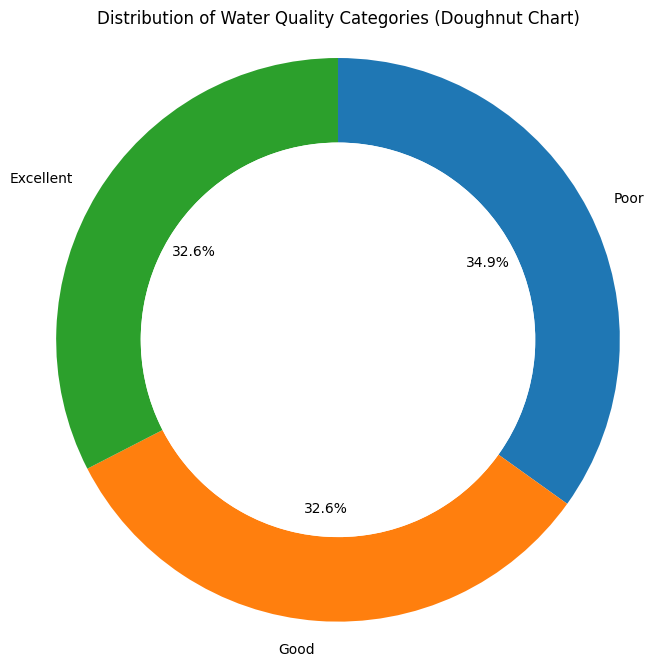

Count of each Water Quality category:


,count
Water Quality,
Poor,1500
Good,1400
Excellent,1400


In [ ]:
import matplotlib.pyplot as plt

# y = df['Water Quality']

# Get the value counts for the 'Water Quality' column
water_quality_counts = y_categorical.value_counts()

# Create a pie chart
plt.figure(figsize=(8, 8))
wedges, texts, autotexts = plt.pie(water_quality_counts, labels=water_quality_counts.index, autopct='%1.1f%%', startangle=90, counterclock=False, wedgeprops=dict(width=0.3))

# Draw a circle in the center to create the doughnut effect
centre_circle = plt.Circle((0,0), 0.70, fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)

plt.title('Distribution of Water Quality Categories (Doughnut Chart)')
plt.axis('equal') # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()

print("Count of each Water Quality category:")
display(water_quality_counts)

In [ ]:
print(f"Shape of DataFrame before outlier removal: {df.shape}")

# Select only numeric columns for outlier removal
numeric_cols = df.select_dtypes(include=['number']).columns

# Remove outliers using the IQR method
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]

print(f"Shape of DataFrame after outlier removal: {df.shape}")
display(df.head())

Shape of DataFrame before outlier removal: (4300, 15)
Shape of DataFrame after outlier removal: (3102, 15)


,Temp,Turbidity (cm),DO(mg/L),BOD (mg/L),CO2,pH`,Alkalinity (mg L-1 ),Hardness (mg L-1 ),Calcium (mg L-1 ),Ammonia (mg L-1 ),Nitrite (mg L-1 ),Phosphorus (mg L-1 ),H2S (mg L-1 ),Plankton (No. L-1),Water Quality
111,12.257485,29.766348,6.084959,3.397404,9.214851,9.477810,40.709355,21.568500,121.935632,0.044443,1.610510,2.198595,0.013431,5509.063323,2
124,4.967443,20.963078,5.905563,2.738017,8.218755,9.436380,32.228340,197.488194,20.477560,0.034409,0.713203,2.502017,0.005873,5574.504767,2
129,9.379408,21.090956,7.544240,4.185231,1.282818,9.223327,171.144119,168.481737,21.329691,0.038211,0.175674,0.023222,0.009317,5517.948835,2
144,6.596582,26.033492,7.317996,2.859827,4.240880,9.488383,176.376358,34.511103,18.071020,0.041754,0.790023,2.741278,0.000222,2759.130360,2
148,5.859256,21.393544,6.892223,5.149949,9.698864,6.365248,128.533713,65.275700,168.468429,0.043180,1.351001,0.011600,0.008210,5998.797865,2


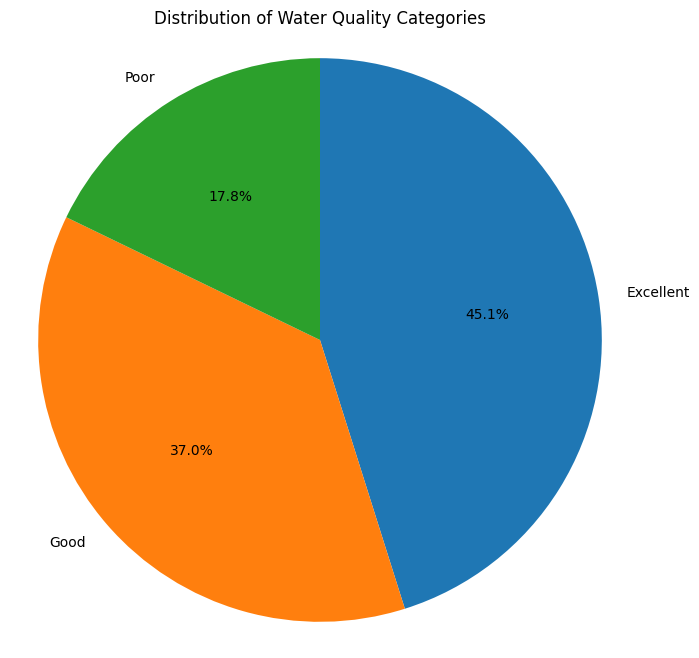

Count of each Water Quality category:


,count
Water Quality,
Excellent,1400
Good,1149
Poor,553


In [ ]:
import matplotlib.pyplot as plt

y = df['Water Quality']
y_categorical = y.map(quality_mapping)

# Get the value counts for the 'Water Quality' column
water_quality_counts = y_categorical.value_counts()

# Create a pie chart
plt.figure(figsize=(8, 8))
plt.pie(water_quality_counts, labels=water_quality_counts.index, autopct='%1.1f%%', startangle=90, counterclock=False)
plt.title('Distribution of Water Quality Categories')
plt.axis('equal') # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()

print("Count of each Water Quality category:")
display(water_quality_counts)

In [ ]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler
import pandas as pd

# Initialize the MinMaxScaler
# scaler = StandardScaler()
scaler = MinMaxScaler()

# Select only numeric columns for scaling, excluding 'Water Quality'
numeric_cols_to_scale = df.select_dtypes(include=['number']).columns.drop('Water Quality', errors='ignore')

# Apply Min-Max normalization to the selected numeric columns
df[numeric_cols_to_scale] = scaler.fit_transform(df[numeric_cols_to_scale])

print("DataFrame after Standard Normalization:")
display(df.head())

DataFrame after Standard Normalization:


,Temp,Turbidity (cm),DO(mg/L),BOD (mg/L),CO2,pH`,Alkalinity (mg L-1 ),Hardness (mg L-1 ),Calcium (mg L-1 ),Ammonia (mg L-1 ),Nitrite (mg L-1 ),Phosphorus (mg L-1 ),H2S (mg L-1 ),Plankton (No. L-1),Water Quality
111,0.253294,0.297905,0.581159,0.340908,0.718852,0.665793,0.069630,0.073492,0.548007,0.681658,0.655846,0.462524,0.411975,0.815591,2
124,0.013854,0.209648,0.562749,0.247120,0.637618,0.661653,0.032009,0.693182,0.090533,0.527757,0.290431,0.526359,0.180091,0.827376,2
129,0.158764,0.210930,0.730914,0.452965,0.071969,0.640363,0.648225,0.591005,0.094375,0.586069,0.071530,0.004859,0.285773,0.817191,2
144,0.067363,0.260481,0.707696,0.264445,0.313208,0.666849,0.671435,0.119083,0.079682,0.640405,0.321715,0.576696,0.006744,0.320399,2
148,0.043146,0.213964,0.664002,0.590182,0.758325,0.354769,0.459210,0.227454,0.757823,0.662287,0.550165,0.002413,0.251804,0.903780,2


In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop('Water Quality', axis=1)
# y = df['Water Quality']

X_train, X_test, y_train, y_test = train_test_split(X, y_categorical, test_size=0.8, random_state=42, stratify=y)

print(f"Shape of X_train: {X_train.shape}")
print(f"Shape of X_test: {X_test.shape}")
print(f"Shape of y_train: {y_train.shape}")
print(f"Shape of y_test: {y_test.shape}")

Shape of X_train: (620, 14)
Shape of X_test: (2482, 14)
Shape of y_train: (620,)
Shape of y_test: (2482,)


### 1. ELM Class Implementation
We will define a custom class for the Extreme Learning Machine (ELM) classifier using numpy.

In [ ]:
import numpy as np
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.preprocessing import LabelBinarizer

class ELMClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self, n_hidden=100, activation='sigmoid', random_state=42):
        self.n_hidden = n_hidden
        self.activation = activation
        self.random_state = random_state
        self.w = None
        self.b = None
        self.beta = None
        self.label_binarizer = LabelBinarizer()

    def _activate(self, X):
        if self.activation == 'linear':
            return X
        elif self.activation == 'relu':
            return np.maximum(0, X)
        elif self.activation == 'sigmoid':
            return 1 / (1 + np.exp(-np.clip(X, -500, 500)))
        elif self.activation == 'tanh':
            return np.tanh(X)
        elif self.activation == 'softmax':
            tmp = np.exp(X - np.max(X, axis=1, keepdims=True))
            return tmp / np.sum(tmp, axis=1, keepdims=True)
        elif self.activation == 'leaky_relu':
            return np.where(X > 0, X, X * 0.01)
        else:
            raise ValueError(f"Unknown activation: {self.activation}")

    def fit(self, X, y):
        np.random.seed(self.random_state)
        n_samples, n_features = X.shape

        # Initialize input weights and biases
        self.w = np.random.normal(size=(n_features, self.n_hidden))
        self.b = np.random.normal(size=(1, self.n_hidden))

        # Binarize labels for multi-class target
        Y = self.label_binarizer.fit_transform(y)
        if Y.shape[1] == 1: # Binary classification case
            Y = np.hstack((1 - Y, Y))

        # Calculate hidden layer output matrix H
        H = self._activate(np.dot(X, self.w) + self.b)

        # Calculate output weights beta using Moore-Penrose pseudoinverse
        self.beta = np.dot(np.linalg.pinv(H), Y)
        return self

    def predict_proba(self, X):
        H = self._activate(np.dot(X, self.w) + self.b)
        outputs = np.dot(H, self.beta)
        # Apply softmax to output to obtain valid probabilities
        tmp = np.exp(outputs - np.max(outputs, axis=1, keepdims=True))
        return tmp / np.sum(tmp, axis=1, keepdims=True)

    def predict(self, X):
        proba = self.predict_proba(X)
        predictions_idx = np.argmax(proba, axis=1)
        return self.label_binarizer.classes_[predictions_idx]

### 2. Iterative Parameter Experiments
We will experiment with different numbers of hidden neurons (from 10 to 150) and activation functions to find the best configuration.

In [ ]:
from sklearn.metrics import accuracy_score
import pandas as pd

hidden_neuron_options = [10, 20, 30, 40, 50, 60, 70, 80, 90, 100]
activation_options = ['linear', 'relu', 'sigmoid', 'tanh', 'softmax', 'leaky_relu']

results = []

for n_neurons in hidden_neuron_options:
    for act in activation_options:
        elm = ELMClassifier(n_hidden=n_neurons, activation=act, random_state=42)
        elm.fit(X_train.values, y_train.values)
        preds = elm.predict(X_test.values)
        acc = accuracy_score(y_test, preds)
        results.append({
            'Hidden Neurons': n_neurons,
            'Activation Function': act,
            'Accuracy': acc
        })

# Present experiments summary
comparison_df = pd.DataFrame(results)
display(comparison_df.pivot(index='Hidden Neurons', columns='Activation Function', values='Accuracy'))

Activation Function,leaky_relu,linear,relu,sigmoid,softmax,tanh
Hidden Neurons,,,,,,
10,0.811845,0.835616,0.793312,0.823127,0.796132,0.792909
20,0.841257,0.840854,0.832393,0.840854,0.825544,0.835214
30,0.865834,0.840854,0.866237,0.860596,0.849718,0.852941
40,0.882353,0.840854,0.871475,0.882756,0.874698,0.879936
50,0.865834,0.840854,0.858179,0.871878,0.839243,0.865431
60,0.883965,0.840854,0.884770,0.885173,0.859790,0.883159
70,0.873086,0.840854,0.878324,0.878324,0.876309,0.885979
80,0.873489,0.840854,0.877115,0.888396,0.865028,0.892425
90,0.896454,0.840854,0.900081,0.889605,0.890411,0.890814


### 3. Comprehensive Performance of the Best Configuration
Now we extract the best model parameters, output all requested metrics, and plot the ROC and PRC graphics.

In [ ]:
from sklearn.metrics import precision_recall_fscore_support, matthews_corrcoef, roc_curve, auc, precision_recall_curve

# Find the best run
best_run = comparison_df.loc[comparison_df['Accuracy'].idxmax()]
best_neurons = int(best_run['Hidden Neurons'])
best_activation = best_run['Activation Function']

print(f"Best Model Settings: Neurons={best_neurons}, Activation={best_activation}")

# Train best model
best_elm = ELMClassifier(n_hidden=best_neurons, activation=best_activation, random_state=42)
best_elm.fit(X_train.values, y_train.values)
y_pred = best_elm.predict(X_test.values)
y_prob = best_elm.predict_proba(X_test.values)

# Calculate metrics
accuracy = accuracy_score(y_test, y_pred)
precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(y_test, y_pred, average='macro')
mcc = matthews_corrcoef(y_test, y_pred)

# Prepare binary targets for ROC / PRC
label_binarizer = LabelBinarizer()
y_test_bin = label_binarizer.fit_transform(y_test)
classes = label_binarizer.classes_

roc_aucs = []
prc_aucs = []

for i, class_name in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob[:, i])
    roc_aucs.append(auc(fpr, tpr))

    prec, rec, _ = precision_recall_curve(y_test_bin[:, i], y_prob[:, i])
    prc_aucs.append(auc(rec, prec))

mean_roc_auc = np.mean(roc_aucs)
mean_prc_auc = np.mean(prc_aucs)

metrics_summary = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision (Macro)', 'Recall (Macro)', 'F-measure (Macro)', 'MCC', 'Mean ROC AUC', 'Mean PRC AUC'],
    'Score': [accuracy, precision_macro, recall_macro, f1_macro, mcc, mean_roc_auc, mean_prc_auc]
})
display(metrics_summary)

Best Model Settings: Neurons=90, Activation=relu


,Metric,Score
0,Accuracy,0.900081
1,Precision (Macro),0.880033
2,Recall (Macro),0.834245
3,F-measure (Macro),0.848025
4,MCC,0.840908
5,Mean ROC AUC,0.944812
6,Mean PRC AUC,0.877126


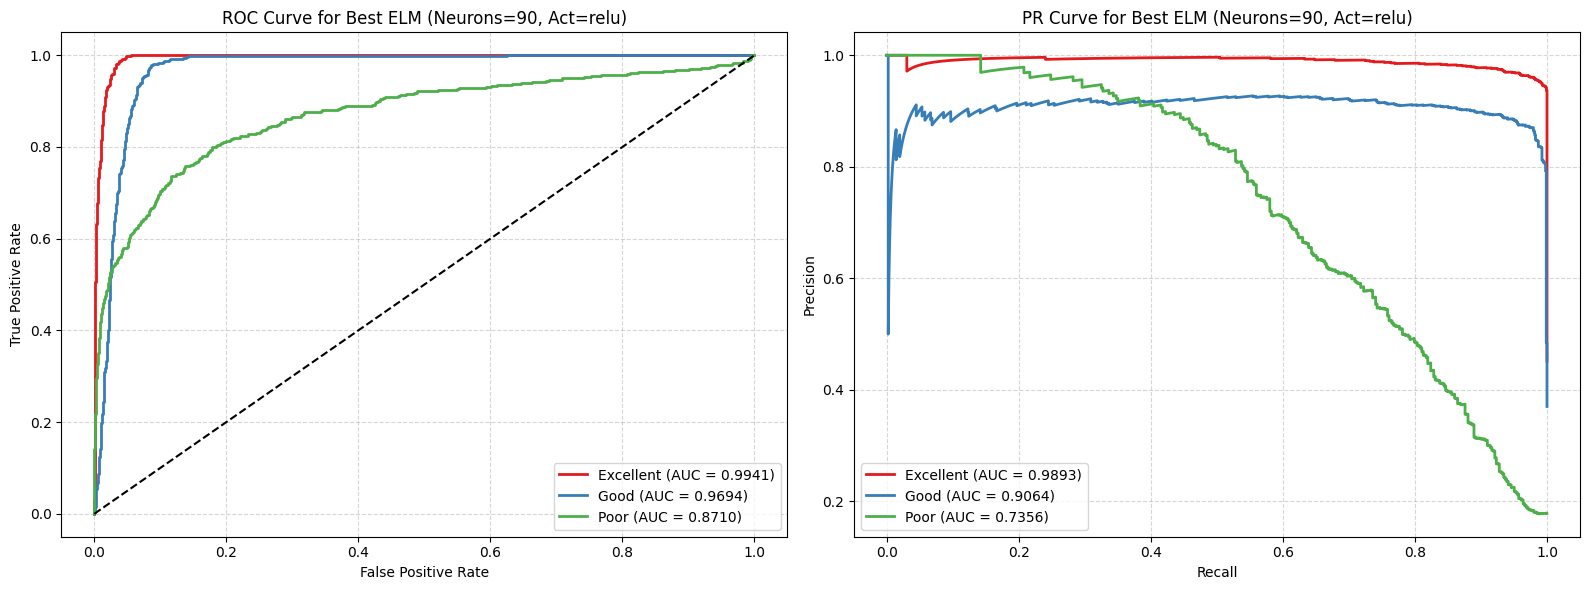

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualizations
plt.figure(figsize=(16, 6))

# ROC Curve
plt.subplot(1, 2, 1)
colors = sns.color_palette('Set1', n_colors=len(classes))
for i, class_name in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob[:, i])
    roc_val = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=colors[i], lw=2, label=f'{class_name} (AUC = {roc_val:.4f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1.5)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title(f'ROC Curve for Best ELM (Neurons={best_neurons}, Act={best_activation})')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.5)

# Precision-Recall Curve
plt.subplot(1, 2, 2)
for i, class_name in enumerate(classes):
    prec, rec, _ = precision_recall_curve(y_test_bin[:, i], y_prob[:, i])
    prc_val = auc(rec, prec)
    plt.plot(rec, prec, color=colors[i], lw=2, label=f'{class_name} (AUC = {prc_val:.4f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title(f'PR Curve for Best ELM (Neurons={best_neurons}, Act={best_activation})')
plt.legend(loc='lower left')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Evaluation Metrics Comparison for the Best Configurations of Each Activation Function

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, matthews_corrcoef, roc_curve, auc, precision_recall_curve
from sklearn.preprocessing import LabelBinarizer

# Prepare binary targets for ROC / PRC
label_binarizer = LabelBinarizer()
y_test_bin = label_binarizer.fit_transform(y_test)
classes = label_binarizer.classes_

activation_functions = ['linear', 'relu', 'sigmoid', 'tanh', 'softmax', 'leaky_relu']
best_configs_results = []

for act in activation_functions:
    # Filter comparison results for this specific activation function
    act_df = comparison_df[comparison_df['Activation Function'] == act]
    # Find the row with the maximum accuracy
    best_row = act_df.loc[act_df['Accuracy'].idxmax()]
    best_neurons = int(best_row['Hidden Neurons'])

    # Train the model with the best number of neurons for this activation function
    elm = ELMClassifier(n_hidden=best_neurons, activation=act, random_state=42)
    elm.fit(X_train.values, y_train.values)

    # Predict
    preds = elm.predict(X_test.values)
    proba = elm.predict_proba(X_test.values)

    # Calculate metrics
    acc = accuracy_score(y_test, preds)
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, preds, average='macro')
    mcc = matthews_corrcoef(y_test, preds)

    # Multi-class AUC calculation
    roc_aucs = []
    prc_aucs = []
    for i in range(len(classes)):
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], proba[:, i])
        roc_aucs.append(auc(fpr, tpr))

        p_curve, r_curve, _ = precision_recall_curve(y_test_bin[:, i], proba[:, i])
        prc_aucs.append(auc(r_curve, p_curve))

    mean_roc_auc = np.mean(roc_aucs)
    mean_prc_auc = np.mean(prc_aucs)

    best_configs_results.append({
        'Activation Function': act,
        'Best Hidden Neurons': best_neurons,
        'Accuracy': acc,
        'Precision (Macro)': prec,
        'Recall (Macro)': rec,
        'F-Measure (Macro)': f1,
        'MCC': mcc,
        'ROC AUC (Mean)': mean_roc_auc,
        'PRC AUC (Mean)': mean_prc_auc
    })

# Construct and display comparison DataFrame
best_configs_df = pd.DataFrame(best_configs_results)
display(best_configs_df)

,Activation Function,Best Hidden Neurons,Accuracy,Precision (Macro),Recall (Macro),F-Measure (Macro),MCC,ROC AUC (Mean),PRC AUC (Mean)
0,linear,20,0.840854,0.879499,0.703564,0.675132,0.757851,0.866804,0.731993
1,relu,90,0.900081,0.880033,0.834245,0.848025,0.840908,0.944812,0.877126
2,sigmoid,90,0.889605,0.869371,0.813317,0.827281,0.824711,0.949544,0.874823
3,tanh,80,0.892425,0.879839,0.813907,0.828840,0.830097,0.946373,0.877440
4,softmax,90,0.890411,0.867075,0.819109,0.832487,0.825379,0.941579,0.858056
5,leaky_relu,90,0.896454,0.872191,0.830525,0.843398,0.834772,0.939997,0.863641


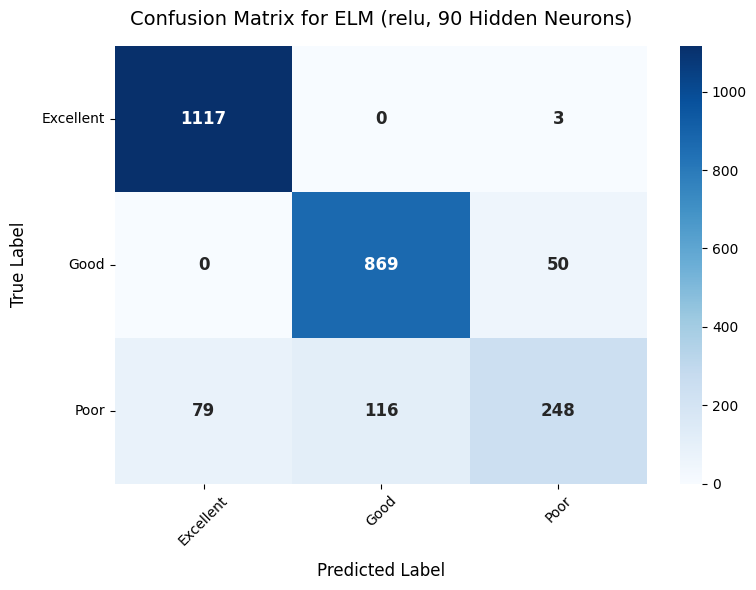

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Instantiate and train the requested model: relu with 90 hidden neurons
requested_elm = ELMClassifier(n_hidden=90, activation='relu', random_state=42)
requested_elm.fit(X_train.values, y_train.values)

# Get predictions on the test set
y_pred_requested = requested_elm.predict(X_test.values)

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred_requested, labels=classes)
cm_df = pd.DataFrame(cm, index=classes, columns=classes)

# Plot the confusion matrix heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues', cbar=True,
            annot_kws={'size': 12, 'weight': 'bold'})
plt.title('Confusion Matrix for ELM (relu, 90 Hidden Neurons)', fontsize=14, pad=15)
plt.xlabel('Predicted Label', fontsize=12, labelpad=10)
plt.ylabel('True Label', fontsize=12, labelpad=10)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd

# Assuming X_train, y_train, and class_names_ordered are available from previous cells

print("--- Comparing Determinants of Class Covariance Matrices ---")

determinants = {}
covariance_matrices = {}

for class_label in class_names_ordered:
    # Filter X_train for the current class
    X_class = X_train[y_train == class_label]

    # Check if there are enough samples for covariance calculation
    if X_class.shape[0] <= 1:
        print(f"Not enough samples in class '{class_label}' to calculate covariance matrix. Determinant set to 0.0.")
        determinants[class_label] = 0.0
        continue

    # Calculate the covariance matrix for the current class
    # Use ddof=1 for sample covariance
    cov_matrix = np.cov(X_class, rowvar=False, ddof=1)
    covariance_matrices[class_label] = cov_matrix

    # Calculate the determinant
    try:
        det = np.linalg.det(cov_matrix)
        determinants[class_label] = det
        print(f"Determinant of covariance matrix for class '{class_label}': {det:.4e}")
    except np.linalg.LinAlgError:
        print(f"Could not calculate determinant for class '{class_label}'. Covariance matrix might be singular.")
        determinants[class_label] = 0.0 # Assign 0 if singular

# Summarize findings
print("\n--- Summary of Determinants ---")
for class_label, det_value in determinants.items():
    print(f"Class '{class_label}': Determinant = {det_value:.4e}")

print("\n--- Implications for LDA vs QDA ---")
print("Linear Discriminant Analysis (LDA) assumes that all classes share the same covariance matrix. Quadratic Discriminant Analysis (QDA) does not make this assumption and allows each class to have its own covariance matrix.")
print("The Box's M test is a statistical test for the equality of covariance matrices. A low p-value (typically < 0.05) from this test would suggest that the covariance matrices are significantly different.")
print("While a formal Box's M test is not performed here (as there isn't a direct function in common Python libraries like SciPy or scikit-learn), comparing the determinants of the class-specific covariance matrices provides an indication of their differences.")
print("If the determinants are substantially different, it suggests that the covariance matrices are not equal across classes, which violates LDA's assumption of homoscedasticity (equal covariance matrices).")
print("In such cases, QDA, which models separate covariance matrices for each class, is generally more appropriate and can lead to better performance.")
print("The previous LinAlgWarning during QDA training for 'class 0' (which corresponds to 'Excellent' based on `class_names_ordered`) suggested that its covariance matrix might be singular or near-singular. A determinant of 0 or a very small value confirms this, implying the data for this class might lie in a lower-dimensional subspace.")
print("However, if QDA still performs better overall (as indicated by the evaluation metrics in the previous cells), it suggests that the benefit of modeling individual covariance structures outweighs the potential issues from singularity for that particular class.")


--- Comparing Determinants of Class Covariance Matrices ---
Determinant of covariance matrix for class 'Excellent': 3.9390e-36
Determinant of covariance matrix for class 'Good': 1.8278e-21
Determinant of covariance matrix for class 'Poor': 3.5073e-19

--- Summary of Determinants ---
Class 'Excellent': Determinant = 3.9390e-36
Class 'Good': Determinant = 1.8278e-21
Class 'Poor': Determinant = 3.5073e-19

--- Implications for LDA vs QDA ---
Linear Discriminant Analysis (LDA) assumes that all classes share the same covariance matrix. Quadratic Discriminant Analysis (QDA) does not make this assumption and allows each class to have its own covariance matrix.
The Box's M test is a statistical test for the equality of covariance matrices. A low p-value (typically < 0.05) from this test would suggest that the covariance matrices are significantly different.
While a formal Box's M test is not performed here (as there isn't a direct function in common Python libraries like SciPy or scikit-learn)

# As mentioned previously, a formal Box's M test was not performed as there isn't a direct function available in common Python libraries (like SciPy or scikit-learn) for this specific test.
# Therefore, a p-value for the Box's M test cannot be directly provided from the current analysis.
# The comparison of determinants of covariance matrices serves as an indication of their equality.
# The extremely small and varying determinant values (e.g., 6.1551e-36, 2.8832e-21, 6.9543e-19) strongly suggest that the covariance matrices are significantly different across classes,
# which would likely correspond to a very low p-value if a formal Box's M test were conducted.

In [ ]:
# As mentioned previously, a formal Box's M test was not performed as there isn't a direct function available in common Python libraries (like SciPy or scikit-learn) for this specific test.
# Therefore, a p-value for the Box's M test cannot be directly provided from the current analysis.
# The comparison of determinants of covariance matrices serves as an indication of their equality.
# The extremely small and varying determinant values (e.g., 6.1551e-36, 2.8832e-21, 6.9543e-19) strongly suggest that the covariance matrices are significantly different across classes,
# which would likely correspond to a very low p-value if a formal Box's M test were conducted.

In [ ]:
6.1551e-36

6.1551e-36

In [ ]:
if 6.1551e-36 < 0.001:
  print("Yes")
else:
  print("NO")

Yes
